Dataset:
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]

 KNN Classification
Accuracy: 0.8338164251207729
Pre

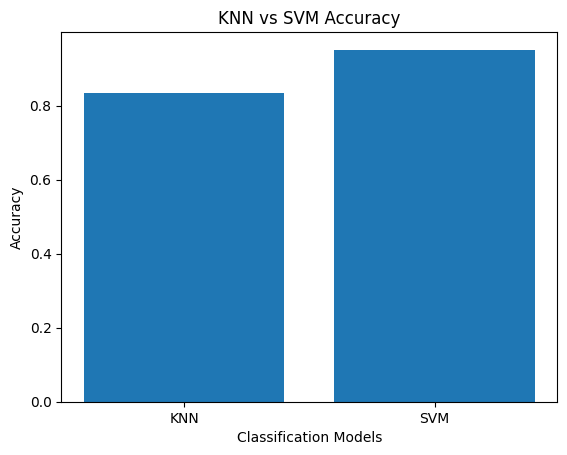

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score, confusion_matrix
from sklearn.metrics import classification_report

# 1. Load Dataset
df = pd.read_csv("/kaggle/input/datasets/balaka18/email-spam-classification-dataset-csv/emails.csv")

print("Dataset:")
print(df.head())

# 2. Preprocessing
df = df.dropna()
df = df.drop_duplicates()

# Separate features and target
X = df.drop(["Email No.", "Prediction"], axis=1)
y = df["Prediction"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 3. KNN Classification
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

# 4. SVM Classification
svm = SVC(kernel="linear")
svm.fit(X_train, y_train)

y_pred_svm = svm.predict(X_test)

# 5. Model Evaluation
def evaluate(name, actual, predicted):
    print("\n", name)
    print("Accuracy:", accuracy_score(actual, predicted))
    print("Precision:", precision_score(actual, predicted))
    print("Recall:", recall_score(actual, predicted))
    print("F1 Score:", f1_score(actual, predicted))

    print("Confusion Matrix:")
    print(confusion_matrix(actual, predicted))

    print("\nClassification Report:")
    print(classification_report(actual, predicted))

evaluate("KNN Classification", y_test, y_pred_knn)

evaluate("SVM Classification", y_test, y_pred_svm)

# 6. Compare Model Accuracy
models = ["KNN", "SVM"]

scores = [
    accuracy_score(y_test, y_pred_knn),
    accuracy_score(y_test, y_pred_svm)
]

plt.bar(models, scores)
plt.title("KNN vs SVM Accuracy")
plt.xlabel("Classification Models")
plt.ylabel("Accuracy")
plt.show()